# ESC-50 · 中文与英文结果 / Bilingual Results

**中文：** 本轮在 Colab Tesla T4 实际完成 65 项开发任务：60 次 60-epoch 神经网络训练、两项传统 baseline、三项鲁棒性任务。本 notebook 是**已经审计结果的自包含阅读器**，不会重新训练。完整训练记录保存在 `ESC50_Matrix_Training_20261028_output.ipynb` 和研究交付包中。所有分数是开发验证结果，不是新的独立测试。

**English:** This round executed 65 development tasks on a Colab Tesla T4: 60 neural runs of 60 epochs, two classical baselines and three stress tasks. This notebook is a **self-contained reader of audited results**, not a retraining notebook. Training execution evidence is retained in `ESC50_Matrix_Training_20261028_output.ipynb` and the research package. All scores below are development-validation measurements, not fresh independent test results.

The readable snapshot below is embedded so tables and plots rerun without audio, weights, Drive access or a GPU. / 下方嵌入可读数据，重画表格与图无需音频、权重、Drive 授权或 GPU。

In [ ]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Saved audited data; no model fitting or evaluation occurs in this notebook.
SNAPSHOT=json.loads(r'''{
"groups": [
{"group": "B_architecture", "model": "cnn_freq", "augmentation": "clean", "case": "", "seeds": "101,202,303", "n_seeds": 3, "complete_three_seeds": true, "accuracy_mean": 0.7261306532663316, "accuracy_sample_sd": 0.0025125628140703626, "macro_f1_mean": 0.7139310897868575, "macro_f1_sample_sd": 0.005810769521043738},
{"group": "B_architecture", "model": "crnn_freq", "augmentation": "clean", "case": "", "seeds": "101,202,303", "n_seeds": 3, "complete_three_seeds": true, "accuracy_mean": 0.7386934673366833, "accuracy_sample_sd": 0.012562814070351758, "macro_f1_mean": 0.7296961202998354, "macro_f1_sample_sd": 0.013580618532447478},
{"group": "B_architecture", "model": "crnn_freq_ca", "augmentation": "clean", "case": "", "seeds": "101,202,303", "n_seeds": 3, "complete_three_seeds": true, "accuracy_mean": 0.7437185929648241, "accuracy_sample_sd": 0.011514009283808656, "macro_f1_mean": 0.7347794490912137, "macro_f1_sample_sd": 0.009974364367689241},
{"group": "B_architecture", "model": "crnn_freq_ta", "augmentation": "clean", "case": "", "seeds": "101,202,303", "n_seeds": 3, "complete_three_seeds": true, "accuracy_mean": 0.7227805695142379, "accuracy_sample_sd": 0.024143275218424767, "macro_f1_mean": 0.7151783700762029, "macro_f1_sample_sd": 0.024105972113922153},
{"group": "B_architecture", "model": "crnn_freq_tca", "augmentation": "clean", "case": "", "seeds": "101,202,303", "n_seeds": 3, "complete_three_seeds": true, "accuracy_mean": 0.7286432160804021, "accuracy_sample_sd": 0.012562814070351758, "macro_f1_mean": 0.7169344652919157, "macro_f1_sample_sd": 0.01352446300574032},
{"group": "C_augmentation", "model": "cnn_freq", "augmentation": "mixup", "case": "", "seeds": "101,202,303", "n_seeds": 3, "complete_three_seeds": true, "accuracy_mean": 0.7160804020100503, "accuracy_sample_sd": 0.006647616359458777, "macro_f1_mean": 0.706536177229569, "macro_f1_sample_sd": 0.004356122853304089},
{"group": "C_augmentation", "model": "cnn_freq", "augmentation": "noise", "case": "", "seeds": "101,202,303", "n_seeds": 3, "complete_three_seeds": true, "accuracy_mean": 0.7311557788944724, "accuracy_sample_sd": 0.008703772902356206, "macro_f1_mean": 0.7199194875758342, "macro_f1_sample_sd": 0.012261597152794335},
{"group": "C_augmentation", "model": "cnn_freq", "augmentation": "specaugment", "case": "", "seeds": "101,202,303", "n_seeds": 3, "complete_three_seeds": true, "accuracy_mean": 0.7185929648241206, "accuracy_sample_sd": 0.011514009283808658, "macro_f1_mean": 0.7075004362358649, "macro_f1_sample_sd": 0.013788174104075325},
{"group": "D_feature_sampling", "model": "cnn", "augmentation": "", "case": "sr16_fmax8_loglinear64", "seeds": "101,202,303", "n_seeds": 3, "complete_three_seeds": true, "accuracy_mean": 0.5159128978224455, "accuracy_sample_sd": 0.008076759431317367, "macro_f1_mean": 0.48576046841389425, "macro_f1_sample_sd": 0.011537425935464403},
{"group": "D_feature_sampling", "model": "cnn", "augmentation": "", "case": "sr16_fmax8_logmel32", "seeds": "101,202,303", "n_seeds": 3, "complete_three_seeds": true, "accuracy_mean": 0.5561139028475712, "accuracy_sample_sd": 0.007253144085296806, "macro_f1_mean": 0.5296946452544379, "macro_f1_sample_sd": 0.00476428180229057},
{"group": "D_feature_sampling", "model": "cnn", "augmentation": "", "case": "sr16_fmax8_logmel64", "seeds": "101,202,303", "n_seeds": 3, "complete_three_seeds": true, "accuracy_mean": 0.5159128978224455, "accuracy_sample_sd": 0.020463637726751444, "macro_f1_mean": 0.48455521251546063, "macro_f1_sample_sd": 0.021950517543921997},
{"group": "D_feature_sampling", "model": "cnn", "augmentation": "", "case": "sr16_fmax8_mfcc40", "seeds": "101,202,303", "n_seeds": 3, "complete_three_seeds": true, "accuracy_mean": 0.4924623115577889, "accuracy_sample_sd": 0.017407545804712345, "macro_f1_mean": 0.47078809074926536, "macro_f1_sample_sd": 0.01746240754376235},
{"group": "D_feature_sampling", "model": "cnn", "augmentation": "", "case": "sr32_fmax16_loglinear64", "seeds": "101,202,303", "n_seeds": 3, "complete_three_seeds": true, "accuracy_mean": 0.4899497487437186, "accuracy_sample_sd": 0.013295232718917546, "macro_f1_mean": 0.46086648670374614, "macro_f1_sample_sd": 0.01741889450286183},
{"group": "D_feature_sampling", "model": "cnn", "augmentation": "", "case": "sr32_fmax16_logmel32", "seeds": "101,202,303", "n_seeds": 3, "complete_three_seeds": true, "accuracy_mean": 0.5711892797319932, "accuracy_sample_sd": 0.010460633163146379, "macro_f1_mean": 0.545928724314909, "macro_f1_sample_sd": 0.015204825827141322},
{"group": "D_feature_sampling", "model": "cnn", "augmentation": "", "case": "sr32_fmax16_logmel64", "seeds": "101,202,303", "n_seeds": 3, "complete_three_seeds": true, "accuracy_mean": 0.5108877721943049, "accuracy_sample_sd": 0.0038380030946028616, "macro_f1_mean": 0.48325013890154556, "macro_f1_sample_sd": 0.0047630518817187275},
{"group": "D_feature_sampling", "model": "cnn", "augmentation": "", "case": "sr32_fmax16_mfcc40", "seeds": "101,202,303", "n_seeds": 3, "complete_three_seeds": true, "accuracy_mean": 0.49581239530988275, "accuracy_sample_sd": 0.031010902146689497, "macro_f1_mean": 0.47291227056131707, "macro_f1_sample_sd": 0.029300406639703177},
{"group": "D_feature_sampling", "model": "cnn", "augmentation": "", "case": "sr32_fmax8_loglinear64", "seeds": "101,202,303", "n_seeds": 3, "complete_three_seeds": true, "accuracy_mean": 0.507537688442211, "accuracy_sample_sd": 0.006647616359458757, "macro_f1_mean": 0.475814774041395, "macro_f1_sample_sd": 0.01570231369265818},
{"group": "D_feature_sampling", "model": "cnn", "augmentation": "", "case": "sr32_fmax8_logmel32", "seeds": "101,202,303", "n_seeds": 3, "complete_three_seeds": true, "accuracy_mean": 0.5569514237855946, "accuracy_sample_sd": 0.010460633163146396, "macro_f1_mean": 0.5300291593013359, "macro_f1_sample_sd": 0.013402739768020226},
{"group": "D_feature_sampling", "model": "cnn", "augmentation": "", "case": "sr32_fmax8_logmel64", "seeds": "101,202,303", "n_seeds": 3, "complete_three_seeds": true, "accuracy_mean": 0.5125628140703518, "accuracy_sample_sd": 0.01962374290428808, "macro_f1_mean": 0.48234573500563543, "macro_f1_sample_sd": 0.02161097048694718},
{"group": "D_feature_sampling", "model": "cnn", "augmentation": "", "case": "sr32_fmax8_mfcc40", "seeds": "101,202,303", "n_seeds": 3, "complete_three_seeds": true, "accuracy_mean": 0.4983249581239531, "accuracy_sample_sd": 0.01710266152149259, "macro_f1_mean": 0.476254229011343, "macro_f1_sample_sd": 0.017273266787155215}
],
"runs": [
{"model": "logistic", "kind": "baseline", "accuracy": "0.4221105527638191", "macro_f1": "0.3886256053887633", "selected_hyperparameter": "0.001"},
{"model": "cepstral_svm", "kind": "baseline", "accuracy": "0.4020100502512563", "macro_f1": "0.37496218594226394", "selected_hyperparameter": "1.0"}
],
"stress": [
{"task_id": "E_clean_cnn", "checkpoint_task": "B_cnn_freq_s101", "condition": "clean", "accuracy": 0.7261306532663316, "macro_f1": 0.719429677059304, "n": 398, "seconds": 3.570849074999387},
{"task_id": "E_clean_cnn", "checkpoint_task": "B_cnn_freq_s101", "condition": "snr_20", "accuracy": 0.47738693467336685, "macro_f1": 0.4462756461405609, "n": 398, "seconds": 3.999838462000298},
{"task_id": "E_clean_cnn", "checkpoint_task": "B_cnn_freq_s101", "condition": "snr_10", "accuracy": 0.23366834170854273, "macro_f1": 0.19591591666217012, "n": 398, "seconds": 3.9263185219997467},
{"task_id": "E_clean_cnn", "checkpoint_task": "B_cnn_freq_s101", "condition": "snr_0", "accuracy": 0.0678391959798995, "macro_f1": 0.042808701879617175, "n": 398, "seconds": 3.9114161789993886},
{"task_id": "E_clean_cnn", "checkpoint_task": "B_cnn_freq_s101", "condition": "gain_-6", "accuracy": 0.6884422110552764, "macro_f1": 0.6720385921268273, "n": 398, "seconds": 3.5857725599998957},
{"task_id": "E_clean_cnn", "checkpoint_task": "B_cnn_freq_s101", "condition": "gain_6", "accuracy": 0.7185929648241206, "macro_f1": 0.7132551177752418, "n": 398, "seconds": 3.4161468810007136},
{"task_id": "E_clean_crnn", "checkpoint_task": "B_crnn_freq_s101", "condition": "clean", "accuracy": 0.7512562814070352, "macro_f1": 0.7421106767329678, "n": 398, "seconds": 3.8379521260003457},
{"task_id": "E_clean_crnn", "checkpoint_task": "B_crnn_freq_s101", "condition": "snr_20", "accuracy": 0.5477386934673367, "macro_f1": 0.5114631947920473, "n": 398, "seconds": 4.146095685999171},
{"task_id": "E_clean_crnn", "checkpoint_task": "B_crnn_freq_s101", "condition": "snr_10", "accuracy": 0.24623115577889448, "macro_f1": 0.23704625309331193, "n": 398, "seconds": 4.130549844000598},
{"task_id": "E_clean_crnn", "checkpoint_task": "B_crnn_freq_s101", "condition": "snr_0", "accuracy": 0.06281407035175879, "macro_f1": 0.044836155072617866, "n": 398, "seconds": 4.3409899090002},
{"task_id": "E_clean_crnn", "checkpoint_task": "B_crnn_freq_s101", "condition": "gain_-6", "accuracy": 0.6984924623115578, "macro_f1": 0.6835588382318089, "n": 398, "seconds": 3.743345299999419},
{"task_id": "E_clean_crnn", "checkpoint_task": "B_crnn_freq_s101", "condition": "gain_6", "accuracy": 0.7336683417085427, "macro_f1": 0.7206955790279926, "n": 398, "seconds": 3.8212997560003714},
{"task_id": "E_noise_cnn", "checkpoint_task": "C_noise_s101", "condition": "clean", "accuracy": 0.7261306532663316, "macro_f1": 0.7128148612653256, "n": 398, "seconds": 3.6358692149997296},
{"task_id": "E_noise_cnn", "checkpoint_task": "C_noise_s101", "condition": "snr_20", "accuracy": 0.7060301507537688, "macro_f1": 0.6820022452981127, "n": 398, "seconds": 4.167745922999529},
{"task_id": "E_noise_cnn", "checkpoint_task": "C_noise_s101", "condition": "snr_10", "accuracy": 0.628140703517588, "macro_f1": 0.5980133414916697, "n": 398, "seconds": 4.185326793000058},
{"task_id": "E_noise_cnn", "checkpoint_task": "C_noise_s101", "condition": "snr_0", "accuracy": 0.2613065326633166, "macro_f1": 0.27007556478609107, "n": 398, "seconds": 4.0841184750006505},
{"task_id": "E_noise_cnn", "checkpoint_task": "C_noise_s101", "condition": "gain_-6", "accuracy": 0.6859296482412061, "macro_f1": 0.6654490356594542, "n": 398, "seconds": 3.7397054450002543},
{"task_id": "E_noise_cnn", "checkpoint_task": "C_noise_s101", "condition": "gain_6", "accuracy": 0.7060301507537688, "macro_f1": 0.6888813524908558, "n": 398, "seconds": 3.61433528499947}
],
"effects": [
{"effect": "added_high_frequency_bandwidth", "left": "D_sr32_fmax8_loglinear64", "right": "D_sr32_fmax16_loglinear64", "n_pairs": 3, "complete_three_seeds": true, "mean_delta_accuracy_pp": -1.7587939698492427, "sample_sd_delta_accuracy_pp": 0.6647616359458789, "mean_delta_macro_f1_pp": -1.4948287337648838},
{"effect": "added_high_frequency_bandwidth", "left": "D_sr32_fmax8_logmel32", "right": "D_sr32_fmax16_logmel32", "n_pairs": 3, "complete_three_seeds": true, "mean_delta_accuracy_pp": 1.4237855946398668, "sample_sd_delta_accuracy_pp": 1.0460633163146333, "mean_delta_macro_f1_pp": 1.589956501357311},
{"effect": "added_high_frequency_bandwidth", "left": "D_sr32_fmax8_logmel64", "right": "D_sr32_fmax16_logmel64", "n_pairs": 3, "complete_three_seeds": true, "mean_delta_accuracy_pp": -0.16750418760469268, "sample_sd_delta_accuracy_pp": 1.7102661521492555, "mean_delta_macro_f1_pp": 0.09044038959101397},
{"effect": "added_high_frequency_bandwidth", "left": "D_sr32_fmax8_mfcc40", "right": "D_sr32_fmax16_mfcc40", "n_pairs": 3, "complete_three_seeds": true, "mean_delta_accuracy_pp": -0.25125628140703626, "sample_sd_delta_accuracy_pp": 1.3989357695552824, "mean_delta_macro_f1_pp": -0.3341958450025902},
{"effect": "attention_ca_vs_gru", "left": "B_crnn_freq", "right": "B_crnn_freq_ca", "n_pairs": 3, "complete_three_seeds": true, "mean_delta_accuracy_pp": 0.5025125628140725, "sample_sd_delta_accuracy_pp": 0.2512562814070307, "mean_delta_macro_f1_pp": 0.5083328791378331},
{"effect": "attention_interaction", "left": "B_crnn_freq_ta+B_crnn_freq_ca-B_crnn_freq", "right": "B_crnn_freq_tca", "n_pairs": 3, "complete_three_seeds": true, "mean_delta_accuracy_pp": 0.08375209380234727, "sample_sd_delta_accuracy_pp": 0.9512409289447755, "mean_delta_macro_f1_pp": -0.3327233575665482},
{"effect": "attention_ta_vs_gru", "left": "B_crnn_freq", "right": "B_crnn_freq_ta", "n_pairs": 3, "complete_three_seeds": true, "mean_delta_accuracy_pp": -1.591289782244554, "sample_sd_delta_accuracy_pp": 1.9024818578895408, "mean_delta_macro_f1_pp": -1.451775022363259},
{"effect": "attention_tca_vs_gru", "left": "B_crnn_freq", "right": "B_crnn_freq_tca", "n_pairs": 3, "complete_three_seeds": true, "mean_delta_accuracy_pp": -1.005025125628134, "sample_sd_delta_accuracy_pp": 1.2562814070351758, "mean_delta_macro_f1_pp": -1.276165500791974},
{"effect": "gru_vs_cnn", "left": "B_cnn_freq", "right": "B_crnn_freq", "n_pairs": 3, "complete_three_seeds": true, "mean_delta_accuracy_pp": 1.256281407035172, "sample_sd_delta_accuracy_pp": 1.3989357695552849, "mean_delta_macro_f1_pp": 1.5765030512977916},
{"effect": "mixup_vs_clean_cnn", "left": "B_cnn_freq", "right": "C_mixup", "n_pairs": 3, "complete_three_seeds": true, "mean_delta_accuracy_pp": -1.005025125628145, "sample_sd_delta_accuracy_pp": 0.5025125628140725, "mean_delta_macro_f1_pp": -0.7394912557288672},
{"effect": "noise_vs_clean_cnn", "left": "B_cnn_freq", "right": "C_noise", "n_pairs": 3, "complete_three_seeds": true, "mean_delta_accuracy_pp": 0.5025125628140689, "sample_sd_delta_accuracy_pp": 1.0952007395830872, "mean_delta_macro_f1_pp": 0.5988397788976715},
{"effect": "representation_vs_logmel64", "left": "D_sr16_fmax8_logmel64", "right": "D_sr16_fmax8_loglinear64", "n_pairs": 3, "complete_three_seeds": true, "mean_delta_accuracy_pp": 0.0, "sample_sd_delta_accuracy_pp": 1.569094974471961, "mean_delta_macro_f1_pp": 0.12052558984335475},
{"effect": "representation_vs_logmel64", "left": "D_sr16_fmax8_logmel64", "right": "D_sr16_fmax8_logmel32", "n_pairs": 3, "complete_three_seeds": true, "mean_delta_accuracy_pp": 4.020100502512565, "sample_sd_delta_accuracy_pp": 1.3295232718917533, "mean_delta_macro_f1_pp": 4.513943273897726},
{"effect": "representation_vs_logmel64", "left": "D_sr16_fmax8_logmel64", "right": "D_sr16_fmax8_mfcc40", "n_pairs": 3, "complete_three_seeds": true, "mean_delta_accuracy_pp": -2.3450586264656645, "sample_sd_delta_accuracy_pp": 2.1071600712578107, "mean_delta_macro_f1_pp": -1.3767121766195285},
{"effect": "representation_vs_logmel64", "left": "D_sr32_fmax16_logmel64", "right": "D_sr32_fmax16_loglinear64", "n_pairs": 3, "complete_three_seeds": true, "mean_delta_accuracy_pp": -2.093802345058624, "sample_sd_delta_accuracy_pp": 1.383811695298012, "mean_delta_macro_f1_pp": -2.2383652197799417},
{"effect": "representation_vs_logmel64", "left": "D_sr32_fmax16_logmel64", "right": "D_sr32_fmax16_logmel32", "n_pairs": 3, "complete_three_seeds": true, "mean_delta_accuracy_pp": 6.030150753768844, "sample_sd_delta_accuracy_pp": 1.2562814070351704, "mean_delta_macro_f1_pp": 6.267858541336348},
{"effect": "representation_vs_logmel64", "left": "D_sr32_fmax16_logmel64", "right": "D_sr32_fmax16_mfcc40", "n_pairs": 3, "complete_three_seeds": true, "mean_delta_accuracy_pp": -1.5075376884422103, "sample_sd_delta_accuracy_pp": 2.7177522176864284, "mean_delta_macro_f1_pp": -1.0337868340228467},
{"effect": "representation_vs_logmel64", "left": "D_sr32_fmax8_logmel64", "right": "D_sr32_fmax8_loglinear64", "n_pairs": 3, "complete_three_seeds": true, "mean_delta_accuracy_pp": -0.5025125628140744, "sample_sd_delta_accuracy_pp": 1.5690949744719578, "mean_delta_macro_f1_pp": -0.653096096424044},
{"effect": "representation_vs_logmel64", "left": "D_sr32_fmax8_logmel64", "right": "D_sr32_fmax8_logmel32", "n_pairs": 3, "complete_three_seeds": true, "mean_delta_accuracy_pp": 4.438860971524285, "sample_sd_delta_accuracy_pp": 2.7561947524127848, "mean_delta_macro_f1_pp": 4.768342429570051},
{"effect": "representation_vs_logmel64", "left": "D_sr32_fmax8_logmel64", "right": "D_sr32_fmax8_mfcc40", "n_pairs": 3, "complete_three_seeds": true, "mean_delta_accuracy_pp": -1.4237855946398668, "sample_sd_delta_accuracy_pp": 1.5956916987652947, "mean_delta_macro_f1_pp": -0.6091505994292422},
{"effect": "sample_rate_matched_bandwidth", "left": "D_sr16_fmax8_loglinear64", "right": "D_sr32_fmax8_loglinear64", "n_pairs": 3, "complete_three_seeds": true, "mean_delta_accuracy_pp": -0.8375209380234542, "sample_sd_delta_accuracy_pp": 0.14506288170593676, "mean_delta_macro_f1_pp": -0.994569437249924},
{"effect": "sample_rate_matched_bandwidth", "left": "D_sr16_fmax8_logmel32", "right": "D_sr32_fmax8_logmel32", "n_pairs": 3, "complete_three_seeds": true, "mean_delta_accuracy_pp": 0.08375209380233987, "sample_sd_delta_accuracy_pp": 1.6347756529265594, "mean_delta_macro_f1_pp": 0.03345140468979935},
{"effect": "sample_rate_matched_bandwidth", "left": "D_sr16_fmax8_logmel64", "right": "D_sr32_fmax8_logmel64", "n_pairs": 3, "complete_three_seeds": true, "mean_delta_accuracy_pp": -0.3350083752093798, "sample_sd_delta_accuracy_pp": 0.14506288170593834, "mean_delta_macro_f1_pp": -0.22094775098252528},
{"effect": "sample_rate_matched_bandwidth", "left": "D_sr16_fmax8_mfcc40", "right": "D_sr32_fmax8_mfcc40", "n_pairs": 3, "complete_three_seeds": true, "mean_delta_accuracy_pp": 0.5862646566164179, "sample_sd_delta_accuracy_pp": 0.38380030946028976, "mean_delta_macro_f1_pp": 0.546613826207761},
{"effect": "specaugment_vs_clean_cnn", "left": "B_cnn_freq", "right": "C_specaugment", "n_pairs": 3, "complete_three_seeds": true, "mean_delta_accuracy_pp": -0.7537688442211069, "sample_sd_delta_accuracy_pp": 1.005025125628145, "mean_delta_macro_f1_pp": -0.6430653550992668}
],
"environment": {
  "python": "3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]",
  "torch": "2.11.0+cu130",
  "numpy": "2.1.3",
  "scipy": "1.16.3",
  "soundfile": "0.14.0",
  "sklearn": "1.6.1",
  "gpu": "Tesla T4",
  "platform": "Linux-6.6.159+-x86_64-with-glibc2.39"
},
"verification": {
  "audited_tasks": 65,
  "neural_runs": 60,
  "epochs_per_neural_run": 60,
  "waveform_replay_models": 62,
  "waveform_replay_clips_each": 398,
  "waveform_replay_changes": 0,
  "same_runtime_resume_equal": true
}
}''')
groups=pd.DataFrame(SNAPSHOT['groups'])
runs=pd.DataFrame(SNAPSHOT['runs'])
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':11,'axes.spines.top':False,'axes.spines.right':False})
print('Audited tasks / 已审计任务:', SNAPSHOT['verification']['audited_tasks'])
print('Runtime used for training / 训练环境:', SNAPSHOT['environment'])

Audited tasks / 已审计任务: 65
Runtime used for training / 训练环境: {'python': '3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]', 'torch': '2.11.0+cu130', 'numpy': '2.1.3', 'scipy': '1.16.3', 'soundfile': '0.14.0', 'sklearn': '1.6.1', 'gpu': 'Tesla T4', 'platform': 'Linux-6.6.159+-x86_64-with-glibc2.39'}


## 数据与方法 / Data and methods

**中文：** 2,000 段五秒录音、50 类。按原始来源隔离，训练 1,200 段、验证 398 段，指定测试角色的 400 段录音本轮不评价。主输入是 16 kHz 单声道的 64 带 Log-Mel，shape `[B,1,64,313]`。CNN 提取局部模式；BiGRU 沿 39 个时间 token 汇总；Temporal Attention 学习时间权重，Channel Attention 调整特征通道。归一化只从训练录音拟合。神经网络均训练 60 轮，按最早最低验证 cross-entropy 选 checkpoint。

**English:** There are 2,000 five-second recordings and 50 classes. Source-strict roles contain 1,200 training, 398 validation and 400 designated test clips; the latter are not evaluated in this round. Main input is 16 kHz mono 64-band Log-Mel, shape `[B,1,64,313]`. The CNN extracts local patterns; the BiGRU aggregates 39 time tokens. Temporal attention learns time weights; channel attention reweights learned feature maps. Normalization uses training clips only. Neural runs train for 60 epochs and select the earliest minimum-validation-cross-entropy checkpoint.

Three seeds describe training variability on the same 398 clips. Their SD is not a confidence interval for new data. / 三个 seed 反复评价同一 398 条录音，其 SD 不是新数据表现的置信区间。

,model,accuracy_mean,accuracy_sample_sd,macro_f1_mean,macro_f1_sample_sd
0,cnn_freq,72.61,0.25,71.39,0.58
1,crnn_freq,73.87,1.26,72.97,1.36
2,crnn_freq_ta,72.28,2.41,71.52,2.41
3,crnn_freq_ca,74.37,1.15,73.48,1.00
4,crnn_freq_tca,72.86,1.26,71.69,1.35


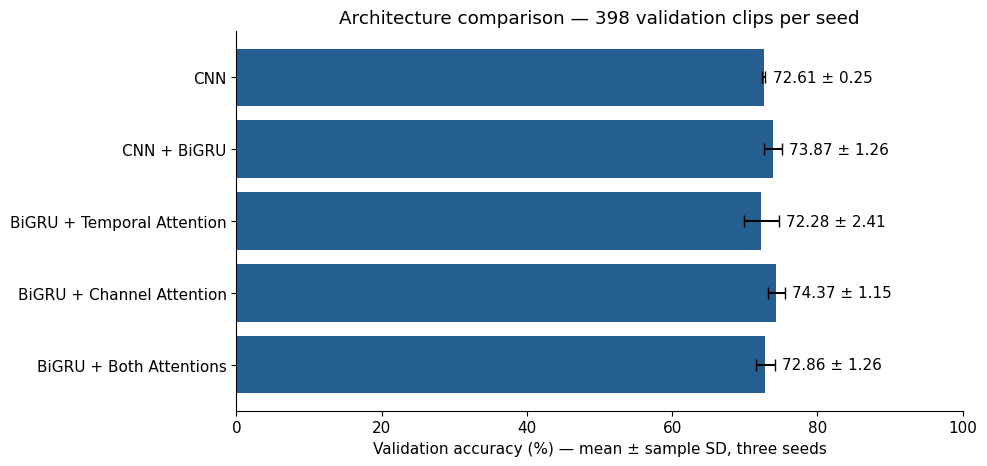

,model,accuracy,macro_f1,selected_hyperparameter
0,logistic,42.21,38.86,0.001
1,cepstral_svm,40.20,37.50,1.0


In [ ]:
models=['cnn_freq','crnn_freq','crnn_freq_ta','crnn_freq_ca','crnn_freq_tca']
labels=['CNN','CNN + BiGRU','BiGRU + Temporal Attention','BiGRU + Channel Attention','BiGRU + Both Attentions']
arch=groups[groups.group.eq('B_architecture')].set_index('model').loc[models].reset_index()
view=arch[['model','accuracy_mean','accuracy_sample_sd','macro_f1_mean','macro_f1_sample_sd']].copy()
for key in view.columns[1:]:view[key]=100*view[key]
display(view.round(2))
fig,ax=plt.subplots(figsize=(10,4.8))
y=np.arange(len(arch));values=100*arch.accuracy_mean.to_numpy();sd=100*arch.accuracy_sample_sd.to_numpy()
ax.barh(y,values,xerr=sd,color='#255F91',capsize=4)
ax.set_yticks(y,labels);ax.invert_yaxis();ax.set_xlim(0,100)
ax.set_xlabel('Validation accuracy (%) — mean ± sample SD, three seeds')
# English chart labels avoid dependence on Chinese fonts in fresh runtimes.
ax.set_title('Architecture comparison — 398 validation clips per seed')
for yy,v,s in zip(y,values,sd):ax.text(v+s+1,yy,f'{v:.2f} ± {s:.2f}',va='center')
plt.tight_layout();plt.show()
base=runs[runs.kind.eq('baseline')][['model','accuracy','macro_f1','selected_hyperparameter']].copy()
for key in ('accuracy','macro_f1'):base[key]=100*base[key].astype(float)
display(base.round(2))

## 训练增强 / Training augmentation

**中文：** SpecAugment 遮挡训练特征；Gaussian noise 以 0.5 概率添加 10–30 dB 噪声；waveform Mixup 同时混合音频和标签损失。验证集始终保持干净。看三个 seed 的均值与代价，而非挑最好一次。

**English:** SpecAugment masks training features; Gaussian noise is added with probability 0.5 at 10–30 dB; waveform Mixup combines audio and label losses. Validation stays clean. Evaluate all seeds and trade-offs rather than selecting the best run.

,augmentation,accuracy_mean,accuracy_sample_sd,macro_f1_mean
0,clean,72.61,0.25,71.39
1,specaugment,71.86,1.15,70.75
2,noise,73.12,0.87,71.99
3,mixup,71.61,0.66,70.65


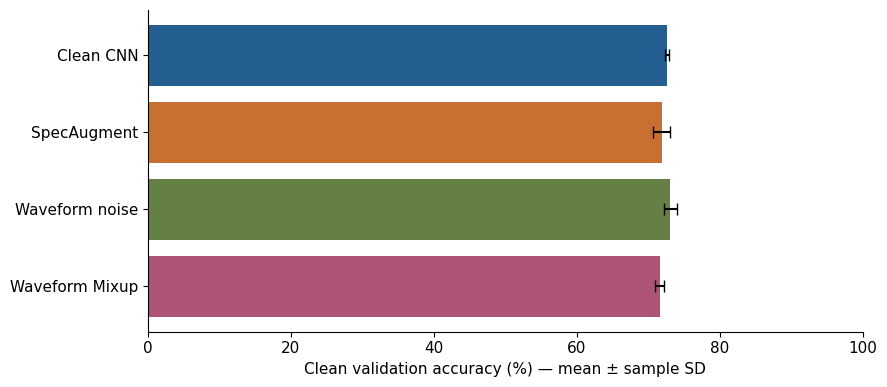

,effect,n_pairs,mean_delta_accuracy_pp,sample_sd_delta_accuracy_pp,mean_delta_macro_f1_pp
4,attention_ca_vs_gru,3,0.503,0.251,0.508
5,attention_interaction,3,0.084,0.951,-0.333
6,attention_ta_vs_gru,3,-1.591,1.902,-1.452
7,attention_tca_vs_gru,3,-1.005,1.256,-1.276
8,gru_vs_cnn,3,1.256,1.399,1.577
9,mixup_vs_clean_cnn,3,-1.005,0.503,-0.739
10,noise_vs_clean_cnn,3,0.503,1.095,0.599
24,specaugment_vs_clean_cnn,3,-0.754,1.005,-0.643


In [ ]:
aug=groups[groups.group.eq('C_augmentation')].copy().set_index('augmentation').loc[['specaugment','noise','mixup']].reset_index()
clean=arch[arch.model.eq('cnn_freq')].copy();clean['augmentation']='clean'
aug=pd.concat([clean,aug],ignore_index=True)
view=aug[['augmentation','accuracy_mean','accuracy_sample_sd','macro_f1_mean']].copy()
for key in view.columns[1:]:view[key]*=100
display(view.round(2))
fig,ax=plt.subplots(figsize=(9,4))
ax.barh(np.arange(4),100*aug.accuracy_mean,xerr=100*aug.accuracy_sample_sd,color=['#255F91','#C77031','#657F45','#AE5478'],capsize=4)
ax.set_yticks(np.arange(4),['Clean CNN','SpecAugment','Waveform noise','Waveform Mixup']);ax.invert_yaxis();ax.set_xlim(0,100)
ax.set_xlabel('Clean validation accuracy (%) — mean ± sample SD')
plt.tight_layout();plt.show()
main_effects=pd.DataFrame(SNAPSHOT['effects'])
display(main_effects[~main_effects.effect.str.startswith(('sample_rate','added_high','representation'))][['effect','n_pairs','mean_delta_accuracy_pp','sample_sd_delta_accuracy_pp','mean_delta_macro_f1_pp']].round(3))

## 特征与采样率 / Features and sampling rates

**中文：** 12 种条件 = 4 种表示 × 3 种采样/带宽条件。D 组统一使用 26,658 参数的频率全局池化 CNN，与主结构组的 `cnn_freq` 不同。16k/F8 → 32k/F8 匹配带宽；32k/F8 → 32k/F16 同时增加高频并改变滤波器间距。参数相同不意味着计算量或物理解释完全相同。

**English:** Twelve cases combine four representations with three sampling/bandwidth conditions. Track D uses the 26,658-parameter frequency-pooled CNN, different from the main `cnn_freq`. The 16k/F8 → 32k/F8 comparison matches bandwidth; 32k/F8 → 32k/F16 adds high frequencies and changes filter spacing. Equal parameters do not establish equal computation or a pure causal interpretation.

,case,accuracy_mean,accuracy_sample_sd,macro_f1_mean
8,sr16_fmax8_loglinear64,51.59,0.81,48.58
9,sr16_fmax8_logmel32,55.61,0.73,52.97
10,sr16_fmax8_logmel64,51.59,2.05,48.46
11,sr16_fmax8_mfcc40,49.25,1.74,47.08
12,sr32_fmax16_loglinear64,48.99,1.33,46.09
13,sr32_fmax16_logmel32,57.12,1.05,54.59
14,sr32_fmax16_logmel64,51.09,0.38,48.33
15,sr32_fmax16_mfcc40,49.58,3.10,47.29
16,sr32_fmax8_loglinear64,50.75,0.66,47.58
17,sr32_fmax8_logmel32,55.70,1.05,53.00


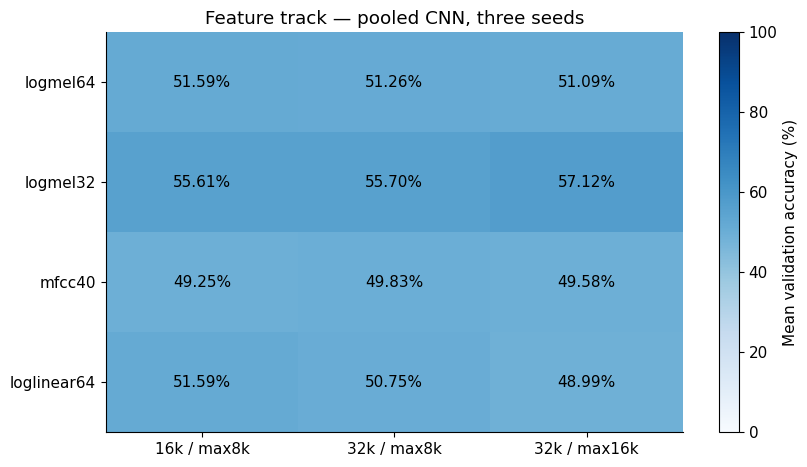

In [ ]:
feature=groups[groups.group.eq('D_feature_sampling')].copy()
view=feature[['case','accuracy_mean','accuracy_sample_sd','macro_f1_mean']].copy()
for key in view.columns[1:]:view[key]*=100
display(view.round(2))
conditions=['sr16_fmax8','sr32_fmax8','sr32_fmax16'];representations=['logmel64','logmel32','mfcc40','loglinear64']
values=np.array([[100*float(feature[feature['case'].eq(c+'_'+f)].accuracy_mean.iloc[0]) for c in conditions] for f in representations])
fig,ax=plt.subplots(figsize=(8.5,4.8));im=ax.imshow(values,vmin=0,vmax=100,cmap='Blues',aspect='auto')
ax.set_xticks(range(3),['16k / max8k','32k / max8k','32k / max16k']);ax.set_yticks(range(4),representations)
for i in range(4):
    for j in range(3):ax.text(j,i,f'{values[i,j]:.2f}%',ha='center',va='center',color='white' if values[i,j]>65 else 'black')
fig.colorbar(im,ax=ax,label='Mean validation accuracy (%)')
ax.set_title('Feature track — pooled CNN, three seeds')
plt.tight_layout();plt.show()

## 噪声与增益 / Noise and gain stress

**中文：** 以下每格 398 条验证录音，每个模型只评价一个 seed101 checkpoint；三个模型使用相同的逐录音确定性扰动。0 dB 指添加噪声与录音 RMS 功率相等。它不是对所有真实噪声和设备的鲁棒性证明。

**English:** Each cell covers 398 validation recordings and one seed101 checkpoint per model, using matched deterministic per-clip corruptions. 0 dB equates added-noise and recording RMS power. This is not proof of robustness to all field noise or devices.

task_id,E_clean_cnn,E_clean_crnn,E_noise_cnn
condition,,,
clean,72.61,75.13,72.61
snr_20,47.74,54.77,70.60
snr_10,23.37,24.62,62.81
snr_0,6.78,6.28,26.13
gain_-6,68.84,69.85,68.59
gain_6,71.86,73.37,70.60


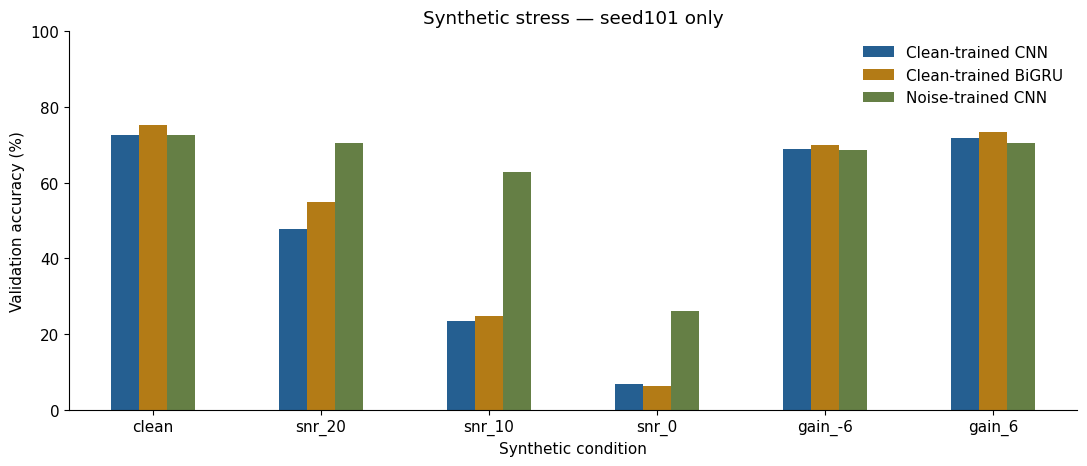

In [ ]:
stress=pd.DataFrame(SNAPSHOT['stress'])
order=['clean','snr_20','snr_10','snr_0','gain_-6','gain_6']
pivot=stress.pivot(index='condition',columns='task_id',values='accuracy').loc[order,['E_clean_cnn','E_clean_crnn','E_noise_cnn']]*100
display(pivot.round(2))
ax=pivot.plot.bar(figsize=(11,4.8),color=['#255F91','#B37B16','#657F45'],rot=0)
ax.set_ylim(0,100);ax.set_ylabel('Validation accuracy (%)');ax.set_xlabel('Synthetic condition')
ax.set_title('Synthetic stress — seed101 only')
ax.legend(['Clean-trained CNN','Clean-trained BiGRU','Noise-trained CNN'],frameon=False)
plt.tight_layout();plt.show()

## 完整性与解释边界 / Verification and interpretation limits

**中文：** Accuracy 是正确录音比例；Macro-F1 让 50 类等权。所有 65 项任务均从逐样本 CSV 重新核算。随后从原始验证 WAV 通过项目前端重新执行 62 个拟合模型，核对全部 24,676 条预测。真实数据断点恢复 probe 也与不中断 pilot 逐位一致。这是内部执行一致性检查，不是外部人类独立复现。

**English:** Accuracy counts correctly classified clips; macro-F1 weights all 50 classes equally. All 65 tasks were audited from prediction CSVs. Replaying 62 fitted models from original validation WAVs matched 24,676 predictions. A real-data epoch-resume probe also matched an uninterrupted pilot bit-for-bit. These are internal execution-consistency checks, not external human replication.

**中文：** 旧项目已经访问过所有 ESC-50 folds。本轮不评价 fold 5，但也不能把已见过的数据重新称为盲测。不要把约 70% 以上的验证分数与旧约 62% 的测试分数相减，声称模型提升。Attention 不是必然有效，模拟噪声也不等于现实鲁棒性；没有 SOTA、算法新颖性、生产部署或学习者掌握的认证。

**English:** The earlier project already accessed every ESC-50 fold. This round does not evaluate fold 5, but cannot restore blindness to previously used data. Do not subtract the old roughly 62% test scores from the new 70%+ validation scores and call the difference improvement. Attention is not guaranteed to help; synthetic noise is not field robustness. No SOTA, algorithmic-novelty, production-readiness or learner-mastery certification is claimed.

In [ ]:
display(pd.DataFrame([SNAPSHOT['verification']]).T.rename(columns={0:'Observed result / 实际结果'}))
assert SNAPSHOT['verification']['audited_tasks']==65
assert SNAPSHOT['verification']['waveform_replay_models']==62
assert SNAPSHOT['verification']['waveform_replay_changes']==0
assert SNAPSHOT['verification']['same_runtime_resume_equal'] is True
print('All saved verification checks passed / 保存的核验全部通过')

,Observed result / 实际结果
audited_tasks,65
neural_runs,60
epochs_per_neural_run,60
waveform_replay_models,62
waveform_replay_clips_each,398
waveform_replay_changes,0
same_runtime_resume_equal,True


All saved verification checks passed / 保存的核验全部通过


## 中文详细说明

# ESC-50 研究：中文内容说明与使用指南

编写日期：2026年10月28日。本指南解释所提供项目的实际实现；本次 Colab 到底完成了哪些实验、测到了什么，请阅读中文结果报告。实验配置、软件测试、历史保存结果和本次新训练，是不同层次的证据。

## 1. 这项研究究竟在解决什么？

输入一段五秒录音，输出狗叫、雨声、敲门声、飞机等50个类别中的一个。模型对**整段录音给出一个类别**，并不标出声音发生的时间，也不分离重叠声音。遇到50类以外的声音，现有分类器也不能可靠地识别为“未知”。

研究围绕三个问题展开：改变模型结构是否有帮助；改变训练增强是否有帮助；改变声音表示和采样率是否有帮助。比较时需要控制其他条件，否则分数变化不能归因于某一个因素。

ESC-50 有2,000段录音，每类40段，官方分成五个 fold。本项目开发协议使用 folds 1–3 训练、fold 4 验证、fold 5 作为指定测试角色。metadata 显示，部分原始录音来源 ID 跨越了 fold；按代码的 source-strict 优先级排除冲突后，得到**1,200段训练、398段验证、400段测试角色录音**，其中两段验证录音被排除。同源 ID 意味着需要防止来源泄露，不等于已证明两个音频片段完全相同。

训练集用于更新模型参数，验证集用于选 checkpoint 和比较方案，测试集应回答预先明确的最终问题。**历史研究已经访问 fold 5，也轮换评价过其他 fold。** 当前实验矩阵不评价 fold 5；新的验证分数不能重新创造一个从未见过的独立确认集。本协议也不是标准的“四折训练、一折测试” benchmark，因此不能直接拿它与论文排行榜数字比较。

## 2. 为什么可以用 CNN 处理声音？

主模型与增强实验的输入通路是：

```text
五秒 WAV → 单声道、16 kHz → 80,000个采样点
         → STFT 功率谱 → 64个 Mel 频带 → 自然对数
         → 仅用训练录音拟合的归一化
         → [batch, 1, 64, 313]
```

波形描述振幅随时间变化。STFT 把波形切成相互重叠的短窗口，观察每个局部区间包含哪些频率。窗口长512点，即32 ms；相邻窗口间隔256点，即16 ms，使用中心填充。Mel filterbank 将相近频率组合成64个频带；取对数压缩功率数值范围。归一化统计量只从训练录音估计，不能拿验证或测试录音来拟合。

张量 `[batch, 1, 64, 313]` 依次表示批大小、一个输入通道、64个频带、313个时间帧。它是一张“时间×频率”的表示，CNN 因而可以寻找局部声学图案。CNN 内部的 channel 是学到的特征图，不是左右声道。

三个 convolution → BatchNorm → ReLU → max-pooling 阶段使用16、32、64个特征通道。主输入经过 encoder 后得到 `[batch, 64, 8, 39]`。

## 3. CNN、BiGRU 和 Attention 分别做什么？

| 矩阵中的模型名 | encoder 之后的实际计算 | 要回答的问题 |
| --- | --- | --- |
| `cnn_freq` | 时间平均，保留“通道×频率位置”，再线性分类 | 小 CNN 能做到什么水平？ |
| `crnn_freq` | 每个时刻展平为512维，送入 BiGRU，平均39个输出 | 利用前后文顺序有没有帮助？ |
| `crnn_freq_ta` | 同样的 BiGRU，以 temporal attention 替代时间平均 | 学习哪些时刻更重要有没有帮助？ |
| `crnn_freq_ca` | 在 BiGRU 之前加入 channel attention，之后时间平均 | 重新分配特征图权重有没有帮助？ |
| `crnn_freq_tca` | 同时使用 channel 和 temporal attention | 两种加权结合是否有帮助？ |

BiGRU 沿正向、反向读取**已经录好的整段声音**，每个方向 hidden size 为64，输出 `[batch, 39, 128]`。它适合离线片段分类；这里没有建立实时、因果的流式识别证据。

Temporal attention 为每个时刻输出一个分数，在时间轴上做 softmax，再计算加权平均：`Σ_t α_t h_t`。权重满足 `α_t ≥ 0`、`Σ_t α_t = 1`。初始化时分数相同，因此起点就是均值池化。例如三个时刻的权重为0.1、0.8、0.1，中间时刻贡献更大；三个权重相等就退化为普通平均。Attention 权重描述模型怎样组合特征，并不能直接证明它找到了真实声源或给出了可靠因果解释。

Channel attention 先对每个 encoder channel 的时间与频率位置求平均，经64 → 8 → 64的小 MLP，再乘上 **2×sigmoid** 门控。门控初始化为1，因此初始不改变特征；其范围是0–2，而非0–1。这是轻量的 SE-style 改编，并非对某篇 Attention 论文的逐项复现。更复杂的结构只是研究假设，是否更好必须看受控实验。

## 4. 为什么矩阵共有65项？

| 组别 | 项数 | 内容 |
| --- | ---: | --- |
| A：传统 baseline | 2 | Log-Mel 时间均值/标准差 + logistic regression；DCT 倒谱统计 + linear SVM |
| B：模型结构 | 15 | 上述五种模型 × seeds 101、202、303 |
| C：数据增强 | 9 | CNN 分别使用 SpecAugment、Gaussian noise、waveform Mixup × 三个 seed |
| D：特征与采样率 | 36 | 十二种特征/采样条件 × 三个 seed，使用独立的频率全局池化 `cnn` |
| E：鲁棒性 | 3 | 用 seed101 的干净 CNN、干净 GRU、加噪训练 CNN，分别做验证集扰动测试 |

Baseline 用于判断深度模型增加的复杂度是否值得。Logistic baseline 将64个 Mel 频带各自沿时间取均值和标准差，得到128维向量。SVM baseline 先对64维 Log-Mel 做正交 DCT-II，取前20个系数，再取时间均值和标准差，得到40维向量；这是项目自定义倒谱 baseline，不是 Piczak SVM 系统的复现。

主神经网络训练配方是60 epochs、batch size 32、AdamW 初始学习率0.001、weight decay 0.0001、cosine 衰减和梯度裁剪。**checkpoint 按最低验证 cross-entropy 选择，并非按最高验证 accuracy 选择。** 不同 seed 改变初始化和训练随机性；三个 seed 可以观察稳定性，但不代表三个独立数据集。

SpecAugment 在训练时遮挡归一化特征的部分时间和频带。Gaussian noise 以0.5概率对每条训练波形加噪，added-noise SNR 从10–30 dB采样。Mixup 以 Beta(0.4,0.4) 系数混合训练波形，损失使用两个标签 cross-entropy 的加权和。例如0.7份狗叫与0.3份雨声混合，训练目标也应保留0.7/0.3的软标签，而不是简单标成“狗”。选 checkpoint 时验证集仍保持干净。

E组另测干净声音、20/10/0 dB白噪声，以及−6/+6 dB增益变化。0 dB表示添加的噪声与原录音 RMS 功率相同；扰动按每段录音缩放且不做峰值裁剪。这能检验一种明确的人工扰动，不能代表对所有房间、麦克风、交通噪声或现实环境都鲁棒。

## 5. 十二种特征实验如何理解？

D组将四种表示与三种条件组合：

| 条件 | 采样率 | 分析频率上限 | FFT / hop |
| --- | ---: | ---: | ---: |
| SR16–F8 | 16 kHz | 8 kHz | 512 / 256点 |
| SR32–F8 | 32 kHz | 8 kHz | 1,024 / 512点 |
| SR32–F16 | 32 kHz | 16 kHz | 1,024 / 512点 |

每种条件仍为五秒、32 ms窗口、16 ms hop、313帧。四种表示是64维 Log-Mel、32维 Log-Mel、对64维 Log-Mel 取前40个 DCT-II 系数的 `mfcc40`，以及64个线性频率三角滤波器的对数功率。这里的 MFCC 约定不做 liftering，也不额外替换第0系数。

SR16–F8 与 SR32–F8 分析带宽都到8 kHz，因此后者没有增加8 kHz以上的信息。SR32–F8 与 SR32–F16 增加高频带，但在频带数量不变时也改变了滤波器间距。这些是有明确边界的具体对照，不能直接推出“采样率越高越好”。

D组用的是频率全局池化 `cnn`，因此32、40、64行输入都保持同样的可训练参数量。它与B组的 `cnn_freq` **不是同一结构**。研究特征作用应在D组内部比较；B组和D组的差异同时包含结构变化。D组 checkpoint 也需要各自的前端，不能直接交给旧的普通 `predict` 命令处理。

## 6. 结果里的 Accuracy 和 Macro-F1 是什么？

Accuracy 是“预测正确的录音数÷全部评价录音数”。例如398条验证录音中正确280条，accuracy 为70.35%；改变一条预测就会改变约0.251个百分点。

Macro-F1 先对50个类别各算 F1，再等权平均。某一类别的 precision 为 `TP/(TP+FP)`，recall 为 `TP/(TP+FN)`，F1 为 `2TP/(2TP+FP+FN)`；该实现对零分母类别记零。它能补充发现“总体分数看起来还行，但某些类别几乎不会识别”的问题。JSON中的指标通常是0–1小数，报告一般转换成百分数，两者不能混淆。

从70%升到72%是提高**2个百分点**，不是相对提高2%。应同时看三个 seed 的结果、均值和波动，干净/扰动表现，以及失败或中断记录。只挑最高分 seed 会夸大效果。即使不对验证集反向传播，反复用同一398条录音挑方案，也可能让整个开发过程对验证集过拟合。

## 7. 文件应该按什么顺序看？

| 文件或目录 | 负责什么 |
| --- | --- |
| `notebooks/ESC50_Colab_Research_Console.ipynb` | 预览计划、pilot和选定任务执行控制台 |
| `configs/colab_study_matrix_v1.json` | 已登记任务清单；与用户提供的独立 JSON 一致 |
| `src/esc50_sound/audio.py`、`data.py` | 声音前端、数据获取、划分、归一化 |
| `models.py`、`training.py`、`augmentation.py` | 结构、训练和仅训练时使用的增强 |
| `baseline.py`、`cepstral.py` | 两种传统分类器 |
| `feature_ablation.py`、`tools/feature_ablation.py` | 独立特征实验与对应命令入口 |
| `evaluation.py`、`inference.py` | 数据集评价与单条新录音预测 |
| `study.py` | 鲁棒性与受控诊断 |
| `results/colab_matrix_20261028/` | 本次执行保存的证据，具体覆盖以结果报告为准 |
| `results/final_study/`、旧notebook和模型包 | 历史证据，不自动等于本次重跑 |

Scheduler、registry、platform 是可选研究组织工具，不是让模型分数提高的算法证据。PANNs、AST、BEATs、CLAP和reinforcement learning 仍是尚未集成的未来项，没有相应可运行任务或分数。

## 8. 怎样运行、怎样恢复？

在项目根目录，主训练通路可直接运行：

```bash
python -m pip install -e '.[dev,baseline,report]'
python -m esc50_sound prepare --root data/ESC-50 --cache data/esc50_features.npz
python -m esc50_sound preflight --root data/ESC-50 --cache data/esc50_features.npz
python -m esc50_sound train --model crnn_freq_ta --seed 101 --epochs 60 \
  --scheduler cosine --device cuda --max-seconds 3600 \
  --output runs/new_ta_seed101
```

控制台的 `plan` 只预览；`pilot` 用独立目录做短运行；`selected` 执行选定的登记任务。两轮 pilot 只能验证通路，不能当作最终研究质量。按从上到下的顺序运行 cell，设置明确任务数量和时间上限，并保存每次输出目录。

对于**新版主训练**在完整 epoch 边界的中断，可以运行：

```bash
python -m esc50_sound resume-train --output runs/new_ta_seed101 --max-seconds 3600
```

`last.pt` 保存最近完整 epoch、optimizer和随机状态；`best.pt` 保存验证选中的推理模型。恢复使用 `last.pt`，要求代码、数据、环境兼容；旧推理 checkpoint 不能凭空变成可恢复训练的 checkpoint。特征实验通路不支持 epoch-resume，应保留中断目录，检查后以新运行标识开始。

Colab 的 `/content` 是临时存储。长任务期间就应下载已完成的日志、预测和权重；使用 Drive 时先验证文件写入及恢复行为。仅保存 notebook 不等于保存 runtime 中的全部文件。实际导出了什么，以本次结果报告为准。判断研究结论时，应依赖完整训练记录和重新核算的逐样本预测，而不是只看一个“completed”标签。

## 9. 原始资料与阅读边界

数据定义来自 [ESC-50 官方仓库](https://github.com/karolpiczak/ESC-50)，GRU 接口来自 [PyTorch 2.11 文档](https://docs.pytorch.org/docs/2.11/generated/torch.nn.GRU.html)。[Squeeze-and-Excitation](https://arxiv.org/abs/1709.01507) 提供通道重标定思想；[SpecAugment](https://arxiv.org/abs/1904.08779) 与 [mixup](https://arxiv.org/abs/1710.09412) 是增强方法的原始论文。本轮核验了这些页面的原始摘要/元信息；项目细节以实际源码为准。这里的通道门控、无 time-warp 的掩码与 waveform Mixup 均是具体改编，不声称完整复现原论文，也不以这些引用证明本项目的实验收益。


## Detailed English guide

# ESC-50 study: explanation and practical guide

Prepared 28 October 2026. This guide explains the supplied implementation. Read the current results report for what the new Colab execution actually completed and measured. A configured experiment, a passing software test, an old saved result and a newly executed training run are different kinds of evidence.

## 1. What question does the project answer?

Given a five-second recording, predict one of 50 environmental-sound classes, such as dog, rain, door knock or airplane. The model produces **one label for the whole clip**. It does not locate individual events in time, separate overlapping sound sources or reliably recognize an unknown class outside ESC-50.

The study asks whether performance changes when we change the classifier, training augmentation or audio representation. Those questions require controlled comparisons: changing several things at once cannot establish which one caused a score difference.

ESC-50 contains 2,000 recordings: 40 per class, organized into five official folds. This project's source-strict development protocol uses folds 1–3 for training, fold 4 for validation and fold 5 as the designated test role. Metadata reveals some shared original-source IDs across folds. Applying the implemented source priority leaves **1,200 training clips, 398 validation clips and 400 test-role clips**; two validation clips are excluded. A shared source ID is a reason to avoid source leakage, not proof that two clips are identical audio.

Training examples update the weights. Validation examples choose the checkpoint and compare candidate recipes. Test examples should answer a final, separately specified question. **The historical project already accessed fold 5 and rotated through other folds.** The current matrix does not evaluate fold 5; new validation results cannot restore an untouched confirmation set. This is also not the standard four-training-fold ESC-50 benchmark, so published benchmark numbers are not directly comparable.

## 2. How does sound become model input?

The main architecture/augmentation track follows this path:

```text
5-second WAV → mono, 16 kHz → 80,000 samples
             → STFT power → 64 Mel bands → natural logarithm
             → normalization fitted on training clips only
             → tensor [batch, 1, 64, 313]
```

A waveform is amplitude over time. The STFT analyzes successive short windows, exposing the frequency content of each local interval. Its window is 512 samples (32 ms), hop 256 samples (16 ms), with centered padding. The Mel filterbank combines nearby frequencies into 64 bands. Logarithms compress the large power range. Normalization puts each input band on a scale estimated from training recordings, without fitting to validation or test examples.

Here `[batch, 1, 64, 313]` means batch size, one input channel, 64 frequency bands and 313 time frames. It is a time–frequency representation, so image-style convolutions can detect local acoustic patterns. “Channel” inside the CNN later means a learned feature map; it does not mean a stereo microphone channel.

The shared encoder has three convolution → BatchNorm → ReLU → max-pooling stages, with 16, 32 and 64 learned channels. For the main 64-band input, its output is `[batch, 64, 8, 39]`.

## 3. What do CNN, GRU and attention change?

| Matrix model | Actual computation after the shared encoder | Question |
| --- | --- | --- |
| `cnn_freq` | Average over time, retain channel × frequency positions, linear classifier | How far does a small CNN go? |
| `crnn_freq` | Flatten each time step to 512 features; bidirectional GRU; average 39 recurrent outputs; classifier | Does sequential context help? |
| `crnn_freq_ta` | Same GRU; learned temporal weighting replaces mean pooling | Does choosing which moments matter help? |
| `crnn_freq_ca` | Learned channel gates before the GRU; mean pooling afterward | Does reweighting learned feature maps help? |
| `crnn_freq_tca` | Channel gates plus temporal attention | Does their combination help? |

The bidirectional GRU reads the **whole recorded clip** in both temporal directions. Its hidden size is 64 per direction, giving `[batch, 39, 128]` recurrent features. This is an offline clip classifier; bidirectionality does not establish causal streaming behavior.

Temporal attention assigns a score to each recurrent token, applies a softmax over time and forms a weighted average. With weights `α_t`, the pooled vector is `Σ_t α_t h_t`, where `α_t ≥ 0` and `Σ_t α_t = 1`. Initialization gives equal scores, so it begins as mean pooling. For example, weights 0.1, 0.8 and 0.1 emphasize the middle of three tokens; equal weights recover the ordinary average. Attention weights show how this mechanism combines representations, not a guaranteed explanation of the true sound source.

Channel attention averages each encoder channel over frequency and time, passes the 64 summaries through a 64 → 8 → 64 MLP, then uses **2 × sigmoid** gates. Gates start at 1, preserving the encoder features initially; their possible range is 0–2, not 0–1. This is a lightweight SE-style adaptation, not a verbatim reproduction of a cited attention paper. Channel attention alone changes emphasis, while temporal attention changes the clip-level time aggregation. Neither structure is guaranteed to improve accuracy.

## 4. What are the 65 tasks?

| Group | Tasks | Meaning |
| --- | ---: | --- |
| A: traditional baselines | 2 | Log-Mel temporal mean/std + multinomial logistic regression; DCT cepstral mean/std + linear SVM |
| B: architecture | 15 | The five models above × seeds 101, 202 and 303 |
| C: augmentation | 9 | CNN with SpecAugment, Gaussian noise or waveform Mixup × three seeds |
| D: features and sampling | 36 | Twelve representations/sample-rate conditions × three seeds, using a separate frequency-pooled `cnn` |
| E: robustness | 3 | Validation stress tests for clean CNN, clean GRU and noise-trained CNN, using seed-101 checkpoints |

A baseline establishes whether deep-model complexity adds useful predictive power. The logistic baseline reduces 64 Mel bands to 128 features: one temporal mean and one temporal standard deviation per band. The SVM uses 20 orthonormal DCT-II coefficients of the 64 Log-Mel bands, then their temporal mean/std: 40 features. It is a project-specific cepstral baseline, not a reproduction of Piczak's SVM system.

The main neural recipe uses 60 epochs, batch size 32, AdamW with initial learning rate 0.001 and weight decay 0.0001, cosine decay and gradient clipping. The selected checkpoint has the lowest validation cross-entropy, not necessarily the highest validation accuracy. Seeds change initialization and training randomness; three seeds help reveal instability, but are not three independent datasets.

**SpecAugment** masks selected normalized frequency/time regions during training. **Noise augmentation** adds Gaussian noise to each training waveform with probability 0.5 and added-noise SNR sampled from 10–30 dB. **Mixup** combines two training waveforms with a Beta(0.4, 0.4) mixing weight and uses the corresponding weighted sum of two cross-entropies. For example, a 0.7 dog + 0.3 rain mixture has a soft training target; calling it only “dog” would discard the label mixture. Validation stays clean for checkpoint selection.

Group E separately measures clean audio, synthetic noise at 20/10/0 dB SNR and gain changes of −6/+6 dB. At 0 dB the added noise and original recording have equal RMS power. Noise is scaled per clip without peak clipping. This controlled white-noise test is not evidence of robustness to all microphones, rooms, traffic noise or real-world deployment conditions.

## 5. Why twelve feature cases?

Group D crosses four representations with three conditions:

| Condition | Sample rate | Analyzed upper frequency | FFT / hop |
| --- | ---: | ---: | ---: |
| SR16–F8 | 16 kHz | 8 kHz | 512 / 256 samples |
| SR32–F8 | 32 kHz | 8 kHz | 1,024 / 512 samples |
| SR32–F16 | 32 kHz | 16 kHz | 1,024 / 512 samples |

All keep five-second duration, 32 ms windows, 16 ms hops and 313 frames. The representations are 64 Log-Mel bands, 32 Log-Mel bands, 40 DCT-II coefficients of 64 Log-Mel bands (`mfcc40`), and 64 linearly spaced triangular log-power bands. The MFCC convention has no liftering or special replacement of coefficient 0.

Comparing SR16–F8 with SR32–F8 holds analyzed bandwidth at 8 kHz; it does not add high-frequency information. Comparing SR32–F8 with SR32–F16 adds the upper band but also changes filter spacing at fixed band count. These are useful controlled contrasts with explicit limits, not a universal claim that higher sample rate is better.

This track uses `cnn`, which pools frequency globally and therefore keeps its parameter count fixed when the input has 32, 40 or 64 rows. It is **different from `cnn_freq`** in group B. Compare feature choices within group D; a B-versus-D difference changes both representation and model. Group-D checkpoints also require their own feature frontend and are not accepted as ordinary legacy `predict` inputs.

## 6. How should I read a result?

**Accuracy** is correctly classified clips divided by all evaluated clips. If 280 of 398 validation clips are correct, accuracy is 70.35%; one clip changes it by about 0.251 percentage points.

**Macro-F1** computes each class's F1 and averages all 50 classes equally. For a class, precision is `TP/(TP+FP)`, recall is `TP/(TP+FN)`, and F1 is `2TP/(2TP+FP+FN)`; an undefined zero-denominator class receives zero in this implementation. Macro-F1 helps reveal classes that a model neglects even when overall accuracy looks reasonable. Both measures range from 0 to 1 in JSON and are usually displayed as percentages.

A difference from 70% to 72% is **2 percentage points**, not 2%. Report all registered seeds, their mean and spread, clean and corrupted scores, and failed or partial runs. Choosing the best seed alone exaggerates performance. Repeated selection on the same 398 clips can overfit the development process even though training never backpropagates through validation.

## 7. Where is the relevant code and evidence?

| Location | Responsibility |
| --- | --- |
| `notebooks/ESC50_Colab_Research_Console.ipynb` | Plan, pilot and selected-task controller |
| `configs/colab_study_matrix_v1.json` | Registered task roster; matches the supplied standalone JSON |
| `src/esc50_sound/audio.py`, `data.py` | Audio frontend, data acquisition, split and normalization |
| `models.py`, `training.py`, `augmentation.py` | Architectures, optimization and training-only transformations |
| `baseline.py`, `cepstral.py` | Traditional classifiers |
| `feature_ablation.py` and `tools/feature_ablation.py` | Separate feature track and its command line |
| `evaluation.py`, `inference.py` | Dataset metrics versus prediction on one new clip |
| `study.py` | Controlled robustness and diagnostic measurements |
| `results/colab_matrix_20261028/` | This execution's retained evidence; consult the results report for exact contents |
| `results/final_study/`, old notebooks, model bundles | Historical research evidence; not automatically new executions |

The scheduler, registry and platform modules are optional research infrastructure. They organize work; their presence does not establish improved classification. PANNs, AST, BEATs, CLAP and reinforcement learning are listed as unavailable/future work, without integrated executable tasks or scores.

## 8. Running and recovering experiments

From the project root, a direct main-track example is:

```bash
python -m pip install -e '.[dev,baseline,report]'
python -m esc50_sound prepare --root data/ESC-50 --cache data/esc50_features.npz
python -m esc50_sound preflight --root data/ESC-50 --cache data/esc50_features.npz
python -m esc50_sound train --model crnn_freq_ta --seed 101 --epochs 60 \
  --scheduler cosine --device cuda --max-seconds 3600 \
  --output runs/new_ta_seed101
```

In the console, `plan` previews without training; `pilot` uses a separate short-run namespace; `selected` executes the chosen registered tasks. A two-epoch pilot verifies operation, not final classification quality. Run cells top to bottom, set explicit task/time caps and preserve each result directory.

For interrupted **new-format main training**, use:

```bash
python -m esc50_sound resume-train --output runs/new_ta_seed101 --max-seconds 3600
```

`last.pt` contains the last complete epoch and optimizer/random states; `best.pt` is the validation-selected inference model. Resume uses `last.pt`, requires compatible code/data/runtime and cannot turn an old inference-only checkpoint into a resumable run. Feature-track runs do not support epoch resume; preserve the incomplete directory and start a new run identity after inspection.

Colab local `/content` storage is temporary. Download completed logs, predictions and weights during execution; if using Drive, verify that writes and recovery work before long batches. A saved notebook alone does not preserve every runtime file. The current results report states what was actually exported. For scientific conclusions, rely on complete training records plus recomputed predictions—not merely a “completed” label.

## 9. Primary references and reading scope

Dataset definitions come from the [official ESC-50 repository](https://github.com/karolpiczak/ESC-50); the GRU interface is documented in [PyTorch 2.11](https://docs.pytorch.org/docs/2.11/generated/torch.nn.GRU.html). [Squeeze-and-Excitation](https://arxiv.org/abs/1709.01507) supplies the channel-recalibration idea; [SpecAugment](https://arxiv.org/abs/1904.08779) and [mixup](https://arxiv.org/abs/1710.09412) are the original augmentation papers. Their primary abstract/metadata pages were checked in this round; implementation details here are established from the actual source. The channel gates, masking without time warping, and waveform Mixup are specific adaptations, not claims of full paper reproduction. These references do not establish performance gains in this project.
